# CIFAR-10 in plain PyTorch

The prototype: one notebook, nothing but PyTorch, torchvision and matplotlib. This is where a
project should start. Everything is in front of you, and any cell can be changed and re-run.

`with_tooling/` is what this notebook grows into once it has to run on a cluster, on several
GPUs, and be compared across many runs.

In [1]:
import random
import time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import Tensor, nn
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms
from torchvision.datasets import CIFAR10
from torchvision.utils import make_grid

## Settings

Every hyperparameter of the run, in one place.

In [2]:
cfg = SimpleNamespace(
    data_dir="data/",
    out_dir="outputs/prototyping/",
    val_size=5000,
    batch_size=128,
    num_workers=4,
    width=64,
    epochs=10,
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4,
    # bf16 autocast needs an Ampere or newer GPU (RTX 30xx and later).
    bf16=torch.cuda.is_available() and torch.cuda.is_bf16_supported(),
    seed=0,
)

In [3]:
def seed_everything(seed: int) -> None:
    """Seed every random number generator the run touches."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


seed_everything(cfg.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name() if device.type == "cuda" else "")

cuda NVIDIA GeForce RTX 3060 Laptop GPU


## Data

CIFAR-10: 50,000 training images, of which 5,000 are held out for validation, and 10,000 test
images. Validation reads the same files as training, without the augmentation.

In [4]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)
CLASSES = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")


def cifar_transforms(augment: bool) -> transforms.Compose:
    """Random crop and flip when augmenting, then normalise."""
    steps = [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()]
    return transforms.Compose(
        [*(steps if augment else []), transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    )


train_full = CIFAR10(cfg.data_dir, train=True, download=True, transform=cifar_transforms(True))
val_full = CIFAR10(cfg.data_dir, train=True, transform=cifar_transforms(False))
test_set = CIFAR10(cfg.data_dir, train=False, download=True, transform=cifar_transforms(False))

# A fixed split, so every run validates on the same images.
perm = torch.randperm(len(train_full), generator=torch.Generator().manual_seed(cfg.seed))
train_set = Subset(train_full, perm[cfg.val_size :].tolist())
val_set = Subset(val_full, perm[: cfg.val_size].tolist())


def make_loader(dataset: Dataset, shuffle: bool) -> DataLoader:
    """Batches of `cfg.batch_size`, loaded by `cfg.num_workers` worker processes."""
    return DataLoader(
        dataset,
        batch_size=cfg.batch_size,
        shuffle=shuffle,
        num_workers=cfg.num_workers,
        pin_memory=device.type == "cuda",
        persistent_workers=cfg.num_workers > 0,
    )


train_loader = make_loader(train_set, shuffle=True)
val_loader = make_loader(val_set, shuffle=False)
test_loader = make_loader(test_set, shuffle=False)
print(f"train {len(train_set)} | val {len(val_set)} | test {len(test_set)} images")

train 45000 | val 5000 | test 10000 images


Always look at a batch before training on it: it catches broken transforms and shuffled
labels.

torch.Size([128, 3, 32, 32]) torch.Size([128])


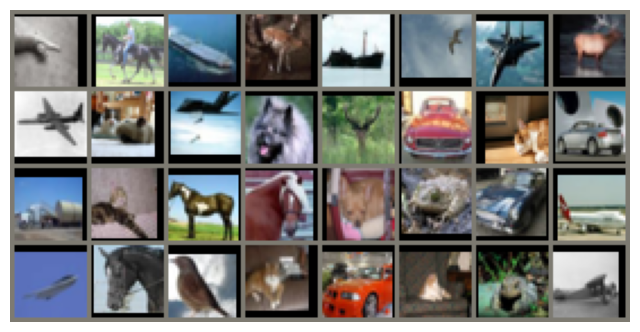

cat horse ship deer ship bird plane deer


In [5]:
images, labels = next(iter(train_loader))
print(images.shape, labels.shape)

grid = make_grid(images[:32], nrow=8)
grid = grid * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)  # un-normalise
plt.figure(figsize=(8, 4.5))
plt.imshow(grid.permute(1, 2, 0).clamp(0, 1))
plt.axis("off")
plt.show()
print(" ".join(CLASSES[i] for i in labels[:8]))

## Model

Three blocks of two 3x3 convolutions, each followed by a max-pool (32 -> 16 -> 8 -> 4 pixels),
then a global average pool and a linear classifier.

In [6]:
def conv_block(c_in: int, c_out: int) -> nn.Sequential:
    """Two 3x3 conv-BN-ReLU layers, then a 2x2 max-pool that halves height and width."""
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )


class SmallCNN(nn.Module):
    """(B, 3, 32, 32) images -> (B, num_classes) logits."""

    def __init__(self, num_classes: int = 10, width: int = 64) -> None:
        """Build the three blocks and the classifier head."""
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, width),
            conv_block(width, 2 * width),
            conv_block(2 * width, 4 * width),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(4 * width, num_classes),
        )

    def forward(self, x: Tensor) -> Tensor:
        """Features, global average pool, then logits."""
        return self.head(self.features(x))

Re-run from here to start a fresh run: the model and the optimiser carry their state from
one run of the training cell to the next.

In [7]:
model = SmallCNN(width=cfg.width).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")
with torch.no_grad():
    print(model(images[:2].to(device)).shape)  # a quick shape check: (2, 10)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=cfg.lr,
    momentum=cfg.momentum,
    weight_decay=cfg.weight_decay,
    nesterov=True,
)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=cfg.lr, total_steps=cfg.epochs * len(train_loader)
)

1.15M parameters
torch.Size([2, 10])


## One pass over the data

Loss and accuracy are kept as sums and counts, and divided once at the end. A mean of per-batch
means would weight a short last batch like a full one.

In [8]:
def train_one_epoch(loader: DataLoader) -> dict[str, float]:
    """Train for one epoch, stepping the LR schedule every batch."""
    model.train()
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    total = 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.bfloat16, enabled=cfg.bf16):
            logits = model(x)
            loss = F.cross_entropy(logits, y)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        scheduler.step()

        loss_sum += loss.detach() * len(y)
        correct += (logits.argmax(dim=-1) == y).sum()
        total += len(y)
    return {"loss": (loss_sum / total).item(), "acc": (correct / total).item()}


@torch.no_grad()
def evaluate(loader: DataLoader) -> dict[str, float]:
    """Mean loss and accuracy over every image the loader yields, without training."""
    model.eval()
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    total = 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.bfloat16, enabled=cfg.bf16):
            logits = model(x)
        loss_sum += F.cross_entropy(logits.float(), y, reduction="sum")
        correct += (logits.argmax(dim=-1) == y).sum()
        total += len(y)
    return {"loss": (loss_sum / total).item(), "acc": (correct / total).item()}

## Train

Validate after every epoch, and keep the checkpoint with the best validation accuracy.

In [9]:
out_dir = Path(cfg.out_dir)
out_dir.mkdir(parents=True, exist_ok=True)
history = {f"{s}_{m}": [] for s in ("train", "val") for m in ("loss", "acc")}
best_acc, best_path = 0.0, out_dir / "best.pt"

for epoch in range(1, cfg.epochs + 1):
    start = time.perf_counter()
    train = train_one_epoch(train_loader)
    val = evaluate(val_loader)
    for split, results in (("train", train), ("val", val)):
        for name, value in results.items():
            history[f"{split}_{name}"].append(value)
    print(
        f"epoch {epoch:3d}/{cfg.epochs} | "
        f"train loss {train['loss']:.3f} acc {train['acc']:.3f} | "
        f"val loss {val['loss']:.3f} acc {val['acc']:.3f} | "
        f"{time.perf_counter() - start:.1f}s"
    )
    if val["acc"] > best_acc:
        best_acc = val["acc"]
        torch.save({"model": model.state_dict(), "epoch": epoch, "cfg": vars(cfg)}, best_path)

epoch   1/10 | train loss 1.328 acc 0.521 | val loss 1.267 acc 0.563 | 9.8s
epoch   2/10 | train loss 0.882 acc 0.692 | val loss 1.049 acc 0.654 | 8.5s
epoch   3/10 | train loss 0.711 acc 0.753 | val loss 1.092 acc 0.670 | 8.6s
epoch   4/10 | train loss 0.605 acc 0.793 | val loss 0.813 acc 0.733 | 8.5s
epoch   5/10 | train loss 0.526 acc 0.820 | val loss 0.703 acc 0.765 | 8.4s
epoch   6/10 | train loss 0.479 acc 0.837 | val loss 0.668 acc 0.789 | 9.3s
epoch   7/10 | train loss 0.421 acc 0.856 | val loss 0.528 acc 0.830 | 8.5s
epoch   8/10 | train loss 0.361 acc 0.877 | val loss 0.411 acc 0.860 | 8.5s
epoch   9/10 | train loss 0.286 acc 0.903 | val loss 0.342 acc 0.882 | 8.7s
epoch  10/10 | train loss 0.228 acc 0.924 | val loss 0.313 acc 0.890 | 8.8s


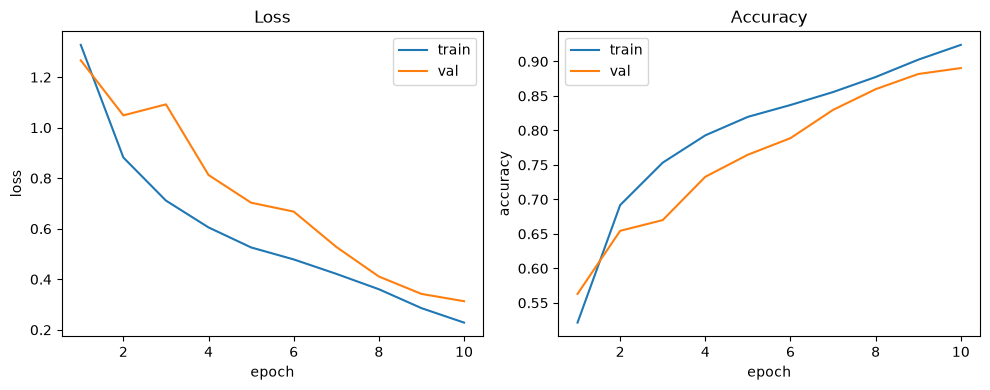

In [10]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10, 4))
for split in ("train", "val"):
    ax_loss.plot(epochs, history[f"{split}_loss"], label=split)
    ax_acc.plot(epochs, history[f"{split}_acc"], label=split)
ax_loss.set(xlabel="epoch", ylabel="loss", title="Loss")
ax_acc.set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
ax_loss.legend()
ax_acc.legend()
fig.tight_layout()
plt.show()

## Test

Once, at the end, on the checkpoint that was best on validation.

In [11]:
model.load_state_dict(torch.load(best_path, map_location=device)["model"])
test = evaluate(test_loader)
print(f"test (best val checkpoint) | loss {test['loss']:.3f} acc {test['acc']:.3f}")

test (best val checkpoint) | loss 0.323 acc 0.893
